# Triagem de reclamações de clientes com rede neural (PLN em português)

**Trabalho 2 de Inteligência Artificial II (2026/02), AMF, Sistemas de Informação**
Integrantes: Mell Campos, Brayan Martins e Nicolas Marin

**Problema.** Lojistas e marketplaces recebem muitas avaliações e mensagens em texto livre e não conseguem ler todas. As reclamações (não chegou, veio quebrado, veio errado, ninguém responde) ficam sem resposta, e o cliente é perdido.

**Solução.** Uma rede neural treinada do zero lê o comentário e diz:
- se é reclamação;
- com que prioridade responder;
- qual o motivo provável.

**Proxy.** No Olist a nota (1 a 5) funciona como rótulo: 1 e 2 contam como reclamação, 4 e 5 como não reclamação. O modelo é pensado para textos que chegam **sem nota** (SAC, WhatsApp, e-mail, redes sociais).

Este notebook roda do começo ao fim no Google Colab, com CPU ou GPU, em cerca de 5 minutos.

## 0. Ambiente
No Colab, clona o repositório e baixa os dados, sem precisar de login no Kaggle. Rodando localmente, dentro da pasta do projeto, só baixa os dados se faltarem.

In [1]:
import os, sys
if os.path.exists("../src"):                        # rodando de dentro de notebooks/ (local)
    %cd ..
if not os.path.exists("src"):                       # Colab: ainda não está na pasta do projeto
    !git clone -q https://github.com/mellcs/Trabalho-IA2.git
    %cd Trabalho-IA2
    !pip -q install -r requirements.txt
from src import baixar_dados
baixar_dados.main("data")

/home/claude/olist/proj
já existe: data/olist_order_reviews_dataset.csv
já existe: data/olist_orders_dataset.csv


In [2]:
import numpy as np, pandas as pd, torch
from IPython.display import Image, Markdown, display
from src import dados, texto, motivos
from src.modelo import treinar, prever, metricas
from src.treinar import baseline_tfidf, fig_eda, fig_palavras, fig_problema, limiares_prioridade, faixa
os.makedirs("results", exist_ok=True)
pd.set_option("display.max_colwidth", 120)
print("PyTorch", torch.__version__)

PyTorch 2.15.0+cu132


## 1. Carga e limpeza
Cada etapa mostra quantas linhas sobram. A remoção de textos duplicados acontece **antes** da divisão em treino, validação e teste. Assim nenhum texto aparece em duas partes, o que evita vazamento.

In [3]:
av = dados.carregar("data")
d, etapas = dados.limpar(av)
display(etapas)
print(f"Base final: {len(d)} comentários, {d['negativo'].mean():.1%} reclamações")
d.sample(5, random_state=1)[["review_score", "negativo", "texto"]]

,etapa,linhas
0,Avaliações no arquivo,100000
1,Com comentário em texto,41726
2,Sem review_id repetido,41404
3,Sem a nota 3 (neutra),37770
4,Sem textos com rótulos conflitantes,34446
5,Sem textos duplicados (base final),30977


Base final: 30977 comentários, 34.2% reclamações


,review_score,negativo,texto
20120,4,0,Muito bom entrega no prazo prometido e o produto correto.
3243,4,0,"Chegou no prazo certo d de ótima qualidade. Recomendo, veio com 4 pilhas"
7366,5,0,Gosto muito de compra na loja pois Sempre chegar certo bom atendimento obrigada pelo caminho
12819,5,0,"Entregaram dentro do prazo eu , recomendo"
26600,5,0,Gostei bastante do peso da faca uma faca leve... vou testar ainda mas pelo visto vai cumprir o que necessito...


## 2. Análise exploratória

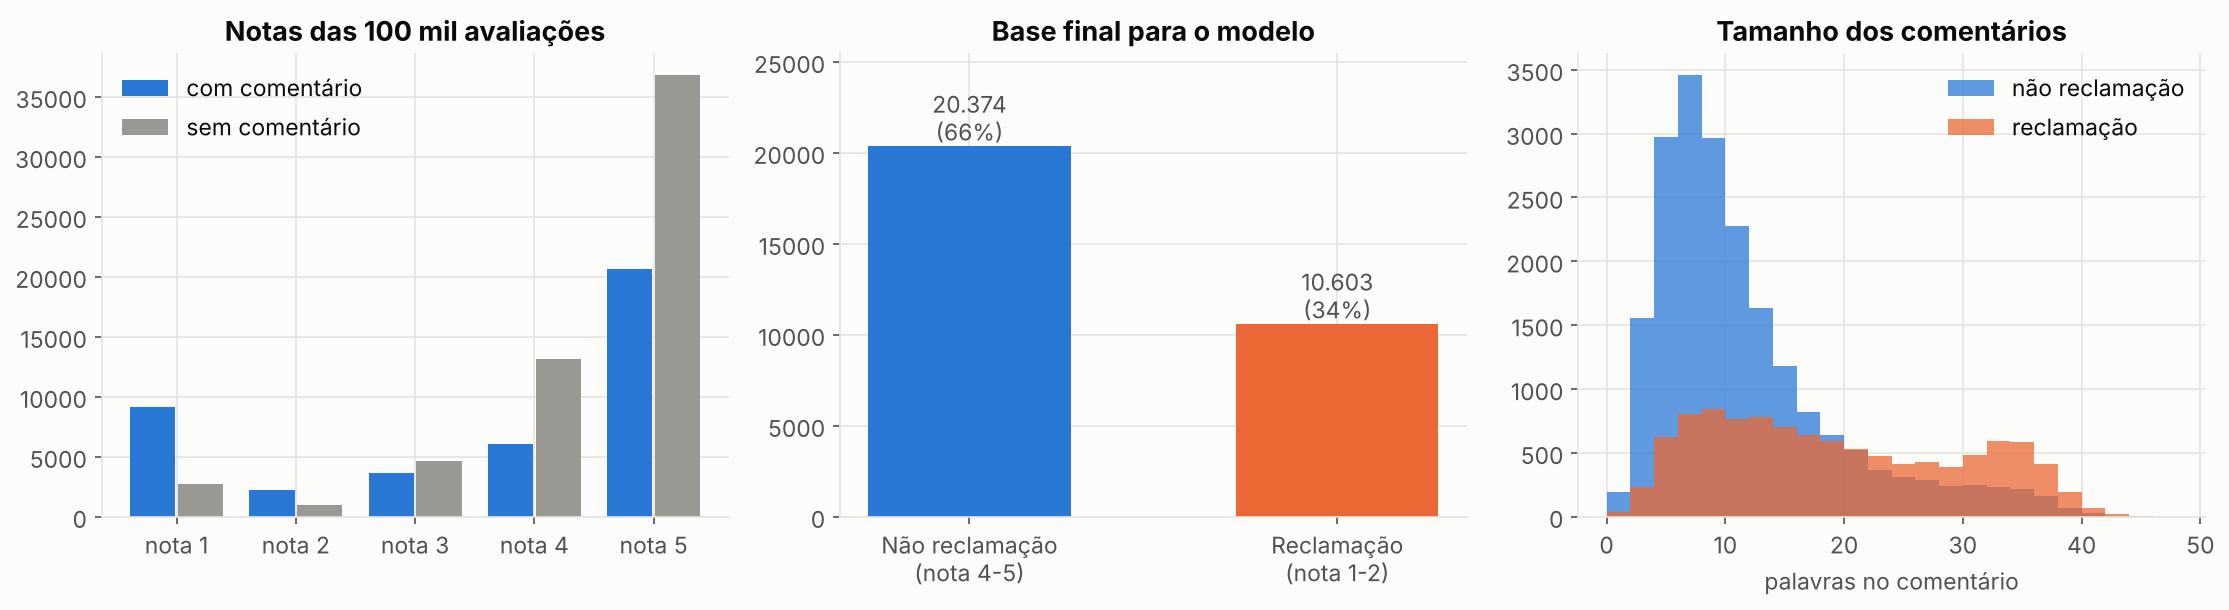

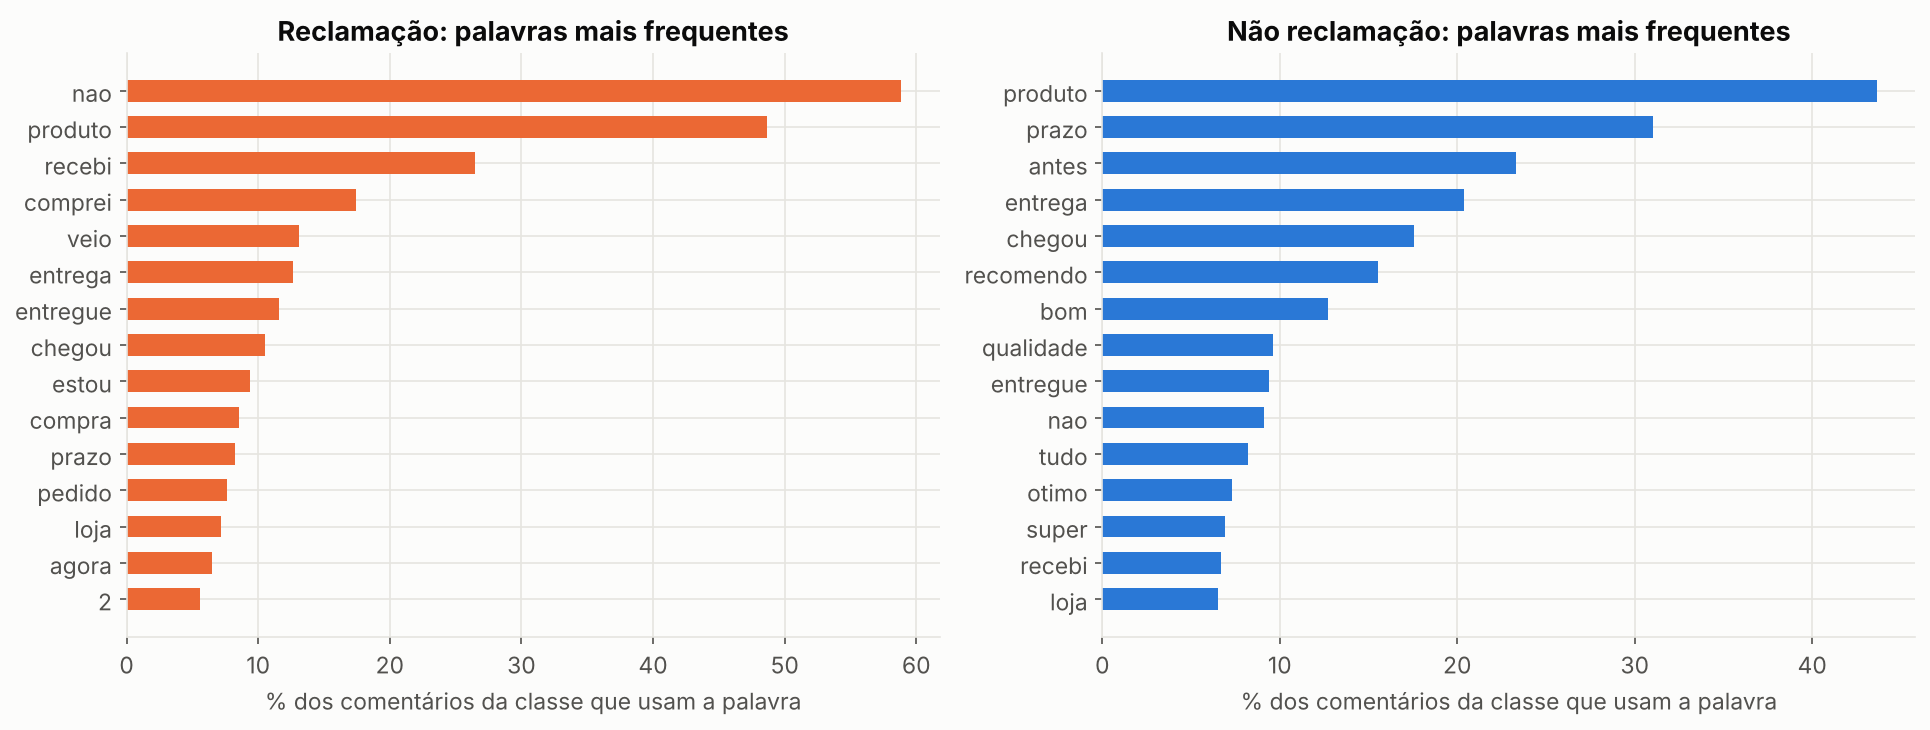

{'mediana_palavras_reclamacao': 17.0, 'mediana_palavras_nao_reclamacao': 9.0}

In [4]:
info = fig_eda(av, d); fig_palavras(d)
display(Image("results/eda.png")); display(Image("results/palavras_frequentes.png"))
info

### O problema em números
O texto não é a única fonte: a tabela de pedidos diz se a entrega atrasou. Juntando as duas, aparece o tamanho do problema.

,taxa_reclamacao,pedidos
Entregue no prazo,0.095561,90445.0
Entregue com atraso,0.628619,6562.0
Não entregue,0.776813,2993.0


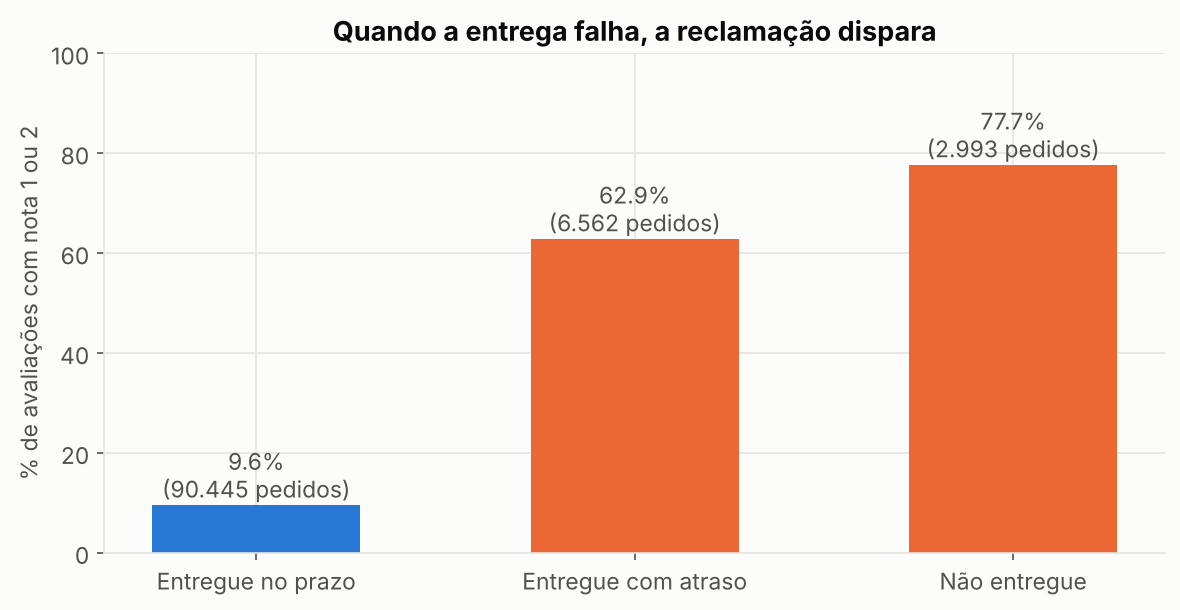

In [5]:
ped = dados.avaliacoes_com_pedidos("data")
display(pd.DataFrame(fig_problema(ped)).T)
display(Image("results/atraso_reclamacao.png"))

## 3. Divisão treino / validação / teste (70/15/15, estratificada)

In [6]:
tr, va, te = dados.dividir(d)
y_tr, y_va, y_te = (x["negativo"].to_numpy() for x in (tr, va, te))
print("treino", len(tr), "| validação", len(va), "| teste", len(te))
print("reclamações:", y_tr.mean().round(3), y_va.mean().round(3), y_te.mean().round(3))

treino 21683 | validação 4647 | teste 4647
reclamações: 0.342 0.342 0.342


## 4. Baseline clássico: TF-IDF (uni e bigramas) + regressão logística balanceada
Serve de régua: se a rede não superar um modelo simples, isso precisa ser dito.

In [7]:
tf, lr = baseline_tfidf()
lr.fit(tf.fit_transform(tr["texto"]), y_tr)
pb_va = lr.predict_proba(tf.transform(va["texto"]))[:, 1]
pd.Series(metricas(y_va, pb_va), name="baseline (validação)").round(4)

F1 (reclamação)          0.8906
Recall (reclamação)      0.9315
Precisão (reclamação)    0.8532
Acurácia                 0.9217
PR-AUC                   0.9410
ROC-AUC                  0.9718
Name: baseline (validação), dtype: float64

## 5. Rede neural própria (PyTorch, treinada do zero)

**Tokenização.** O texto vai para minúsculas e perde os acentos ("não" e "nao" viram o mesmo token). A pontuação é descartada e o "não" é mantido, porque a negação muda o sentido.

**Vocabulário.** Montado só com o treino; palavras com menos de 2 ocorrências viram `<UNK>`.

**Arquitetura principal (BiLSTM).**
```
tokens (60) → Embedding (100) → BiLSTM (64 por direção) → [máximo ‖ média] → Dropout 0,4 → Linear → logit → sigmoide
```
- **Embedding:** cada palavra vira um vetor aprendido. Palavras usadas em contextos parecidos ficam próximas, como "péssimo" e "horrível".
- **BiLSTM:** lê a frase em ordem, nos dois sentidos, e por isso distingue "não chegou" de "chegou".
- **Pooling (máximo e média):** resume a frase num vetor de tamanho fixo.
- **Perda:** BCE com `pos_weight`, porque as reclamações são só um terço da base.
- **Treino:** Adam com lr 1e-3 e *early stopping* pelo F1 da validação (paciência 3).

Também treinamos uma **CNN 1D** (filtros de 2, 3 e 4 palavras) para comparar.

In [8]:
voc = texto.Vocabulario().ajustar(tr["texto"])
X_tr, X_va, X_te = (voc.codificar(x["texto"].tolist()) for x in (tr, va, te))
print("vocabulário:", len(voc), "palavras | exemplo codificado:")
print(tr["texto"].iloc[0]); print(X_tr[0][:20])

vocabulário: 5585 palavras | exemplo codificado:
Loja correta produto chegou em perfeito estado.
[3255 1466 4298 1092 1976 3982 2254    0    0    0    0    0    0    0
    0    0    0    0    0    0]


In [9]:
redes = {}
for arq in ["bilstm", "cnn"]:
    redes[arq] = treinar(arq, len(voc), X_tr, y_tr, X_va, y_va, semente=42)
    print()

[bilstm] época  1  perda treino 0.5623  perda val 0.3969  F1 val 0.8308  (11s)


[bilstm] época  2  perda treino 0.3908  perda val 0.3402  F1 val 0.8593  (10s)


[bilstm] época  3  perda treino 0.3374  perda val 0.3192  F1 val 0.8670  (22s)


[bilstm] época  4  perda treino 0.3107  perda val 0.3148  F1 val 0.8724  (10s)


[bilstm] época  5  perda treino 0.2918  perda val 0.3036  F1 val 0.8785  (10s)


[bilstm] época  6  perda treino 0.2712  perda val 0.3037  F1 val 0.8828  (10s)


... (17 outputs left out)

[cnn] época 12  perda treino 0.2494  perda val 0.2853  F1 val 0.8916  (10s)


[cnn] época 13  perda treino 0.2485  perda val 0.2884  F1 val 0.8892  (10s)


[cnn] época 14  perda treino 0.2409  perda val 0.3046  F1 val 0.8872  (11s)


[cnn] época 15  perda treino 0.2295  perda val 0.2904  F1 val 0.8889  (11s)


In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for arq, (m, h) in redes.items():
    h = pd.DataFrame(h)
    ax[0].plot(h.epoca, h.perda_treino, "o-", label=f"{arq} treino"); ax[0].plot(h.epoca, h.perda_val, "s--", label=f"{arq} validação")
    ax[1].plot(h.epoca, h.f1_val, "o-", label=arq)
ax[0].set_title("Perda por época"); ax[1].set_title("F1 (reclamação) na validação"); ax[0].legend(); ax[1].legend(); plt.show()
f1v = {arq: metricas(y_va, prever(m, X_va))["F1 (reclamação)"] for arq, (m, _) in redes.items()}
escolhida = max(f1v, key=f1v.get); rede = redes[escolhida][0]
print("F1 validação:", {k: round(v, 4) for k, v in f1v.items()}, "→ escolhida:", escolhida)
print(rede); print("parâmetros:", sum(p.numel() for p in rede.parameters()))

F1 validação: {'bilstm': 0.8915, 'cnn': 0.8916} → escolhida: cnn
CNN1D(
  (emb): Embedding(5585, 100, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(100, 100, kernel_size=(2,), stride=(1,), padding=(1,))
    (1): Conv1d(100, 100, kernel_size=(3,), stride=(1,), padding=(2,))
    (2): Conv1d(100, 100, kernel_size=(4,), stride=(1,), padding=(3,))
  )
  (drop): Dropout(p=0.4, inplace=False)
  (saida): Linear(in_features=300, out_features=1, bias=True)
)
parâmetros: 649101


## 6. Avaliação no TESTE (aberto uma única vez)

In [11]:
p_te = prever(rede, X_te); pb_te = lr.predict_proba(tf.transform(te["texto"]))[:, 1]
tab = pd.DataFrame({f"Rede ({escolhida})": metricas(y_te, p_te), "Baseline TF-IDF + LR": metricas(y_te, pb_te)}).T.round(4)
display(tab)
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_te, (p_te >= .5).astype(int), ax=ax[0], display_labels=["não", "reclamação"], colorbar=False); ax[0].set_title("Rede")
ConfusionMatrixDisplay.from_predictions(y_te, (pb_te >= .5).astype(int), ax=ax[1], display_labels=["não", "reclamação"], colorbar=False); ax[1].set_title("Baseline")
plt.show()

,F1 (reclamação),Recall (reclamação),Precisão (reclamação),Acurácia,PR-AUC,ROC-AUC
Rede (cnn),0.8956,0.9308,0.8630,0.9258,0.9371,0.9729
Baseline TF-IDF + LR,0.8985,0.9409,0.8598,0.9273,0.9338,0.9723


**Leitura honesta.** A rede e o baseline ficam praticamente empatados. Os comentários são curtos (mediana de 11 palavras), e expressões como "não recebi" e "veio quebrado" já aparecem como bigramas no TF-IDF. Com cerca de 22 mil exemplos de treino, a rede aprende os embeddings do zero e não tem muita vantagem.

A vantagem da rede aparece em frases em que a ordem e o contexto importam (ver a análise de erros). Além disso, os embeddings que ela aprende servem de base para evoluções, como mais classes e transferência para outros canais.

**Sobre a escolha da arquitetura:** com uma única semente, BiLSTM e CNN empatam na validação (diferença na quarta casa decimal), e qualquer uma pode sair escolhida aqui. No pipeline completo (`python -m src.treinar`, 3 sementes), a BiLSTM teve o melhor F1 médio na validação (0,893 contra 0,889) e é o modelo salvo em `models/` e usado no app.

## 7. Prioridade de atendimento
Os limiares são escolhidos na **validação**:
- **Alta:** pelo menos 95% são reclamações de verdade.
- **Baixa:** no máximo 2% são reclamações.
- **Média:** o resto, que vale uma leitura humana.

In [12]:
lim = limiares_prioridade(y_va, prever(rede, X_va)); print(lim)
fx = faixa(p_te, lim)
pd.DataFrame({"% dos comentários": pd.Series(fx).value_counts(normalize=True),
              "% que são reclamação": pd.Series(y_te).groupby(fx).mean(),
              "% de todas as reclamações": pd.Series(y_te).groupby(fx).sum() / y_te.sum()}).loc[["Alta", "Média", "Baixa"]].round(3)

{'alta': 0.96, 'baixa': 0.19}


,% dos comentários,% que são reclamação,% de todas as reclamações
Alta,0.216,0.946,0.597
Média,0.209,0.622,0.380
Baixa,0.575,0.014,0.023


## 8. Análise de erros

In [13]:
te2 = te.assign(p=p_te)
print("FALSOS POSITIVOS (nota 4-5, rede disse reclamação):")
display(te2[(te2.negativo == 0) & (te2.p >= .5)].nlargest(6, "p")[["p", "review_score", "texto"]])
print("FALSOS NEGATIVOS (nota 1-2, rede disse não reclamação):")
display(te2[(te2.negativo == 1) & (te2.p < .5)].nsmallest(6, "p")[["p", "review_score", "texto"]])

FALSOS POSITIVOS (nota 4-5, rede disse reclamação):


,p,review_score,texto
1196,0.999735,4,Até agora não recebi o produto. Ninguém me dá um retorno
4607,0.999500,4,"Não recebi o produto, enviei mensagem não me responderam, liguei estou esperando até agora o retorno"
4270,0.998279,4,Não comprei esse produto e nem e o numero do meu cartão. Aguardo retorno
1419,0.998232,4,Solicitei a devolução porém não recebi os procedimentos... Produto diferente da foto no site
1614,0.997953,5,Não foi entregue o meu pedido
1942,0.997597,4,"Enviaram o produto errado pra mim!\r\nNa loja virtual estava mostrando o produto original, eu comprei, e chegou um p..."


FALSOS NEGATIVOS (nota 1-2, rede disse não reclamação):


,p,review_score,texto
2215,0.000043,2,muito bom gostei do atendimento veio bem antes do prazo
4571,0.000065,2,Linda.entrega rápida... parabéns
4346,0.000165,1,"Ótima loija produto entregue dentro do prazo,Produto muito bom"
3249,0.001140,1,Super recomendo lannister. Entrega tudo no prazo. 🖒🖒👏👏👏
210,0.001381,1,Bom produto: superou as minhas espectativas
2925,0.002377,1,Sai mto rapido


Padrões típicos de erro:
- **Falsos positivos:** o cliente relata um problema, mas dá nota alta porque foi resolvido ("atrasou, mas a loja resolveu").
- **Falsos negativos:** textos neutros ou elogiosos com nota baixa, como "produto bom" com nota 1, em que a nota provavelmente reflete outra coisa, como frete ou um item faltando.

Muitos desses erros são **ruído do rótulo**, porque o texto e a nota contam histórias diferentes. Não são falhas de leitura do modelo.

## 9. Motivo das reclamações (diferencial)
Não há rótulo de motivo, então usamos regras de palavras-chave, que são transparentes. A regra de entrega é conferida com um dado independente: a situação real do pedido.

In [14]:
neg = te2[te2.p >= .5].assign(motivo=lambda x: x.texto.map(motivos.motivo))
neg = neg.merge(ped[["review_id", "entrega"]].drop_duplicates("review_id"), on="review_id", how="left")
res = neg.groupby("motivo").agg(comentarios=("texto", "size"), pedido_com_falha_na_entrega=("entrega", lambda s: (s != "Entregue no prazo").mean()))
res["%"] = res.comentarios / res.comentarios.sum()
res.sort_values("comentarios", ascending=False).round(3)

,comentarios,pedido_com_falha_na_entrega,%
motivo,,,
Entrega / atraso,827,0.585,0.482
Pedido incompleto,210,0.119,0.122
Outros / não identificado,204,0.221,0.119
Produto diferente / errado,201,0.045,0.117
Atendimento / reembolso,138,0.500,0.080
Produto com defeito / qualidade,135,0.037,0.079


## 10. Demonstração
O modelo final (salvo em `models/` pelo `python -m src.treinar`) é carregado pelo app em Gradio. Aqui usamos a mesma classe do app.

In [15]:
from src.inferencia import Analisador
A = Analisador("models")
for t in ["Comprei faz duas semanas e até agora não chegou, ninguém responde meu e-mail",
          "Produto excelente, chegou antes do prazo e muito bem embalado. Recomendo!",
          "O produto é bonito, mas veio uma peça a menos e a cor é diferente da foto",
          "Chegou rápido, mas parou de funcionar no segundo dia"]:
    r = A.analisar(t)
    print(f"{r['probabilidade']:.0%} | {r['prioridade']:5} | {r['motivo']:32} | {t}")

100% | Alta  | Entrega / atraso                 | Comprei faz duas semanas e até agora não chegou, ninguém responde meu e-mail
0% | Baixa | —                                | Produto excelente, chegou antes do prazo e muito bem embalado. Recomendo!
96% | Média | Produto diferente / errado       | O produto é bonito, mas veio uma peça a menos e a cor é diferente da foto
0% | Baixa | —                                | Chegou rápido, mas parou de funcionar no segundo dia


In [16]:
# Para abrir o app no Colab com link público, descomente:
# from app import criar_app; criar_app().launch(share=True)

## Limitações e próximos passos
- **Proxy:** a nota não é uma anotação manual do sentimento do texto. Antes de usar em SAC, WhatsApp ou redes sociais, é preciso validar com mensagens reais desses canais.
- **Viés de amostra:** só cerca de 42% dos clientes escrevem comentário.
- **Nota 3 fora:** com três classes, a neutra ficou com F1 de 0,28 no baseline. Um próximo passo é anotar manualmente uma amostra de neutros.
- **Próximos passos:** modelos pré-treinados em português (por exemplo, BERTimbau), classificador de motivo treinado com rótulos manuais e integração com o atendimento do lojista (fila priorizada).